# When should mosquito control start? A dengue SIR model for Colombo, calibrated with MCMC

[One-paragraph summary, written last: the problem, the model, the key result and how it was verified.]

In [5]:
# Setup: imports, random seed and data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                      # every random result in this notebook uses this seed
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__)

# Use the local copy when the repository is cloned; download it on a fresh Colab runtime.
DATA_URL = "https://raw.githubusercontent.com/geethsenaviratne/dengue-sir-mcmc-colombo/main/data/colombo_2017.csv"
try:
    cases = pd.read_csv("../data/colombo_2017.csv")
except FileNotFoundError:
    cases = pd.read_csv(DATA_URL)

assert len(cases) == 52 and cases["week"].tolist() == list(range(1, 53)), "expected 52 consecutive weeks of 2017"
cases.head()

numpy 2.5.5 | pandas 3.1.1


,year,week,start_date,end_date,cases
0,2017,1,2016-12-31,2017-01-06,342
1,2017,2,2017-01-07,2017-01-13,531
2,2017,3,2017-01-14,2017-01-20,565
3,2017,4,2017-01-21,2017-01-27,482
4,2017,5,2017-01-28,2017-02-03,417


## 1. Problem and question

In 2017, Colombo district had its largest dengue epidemic in the weekly records that begin in 2007. Reported cases rose from a few hundred a week early in the year to 1,972 in the week beginning 15 July, then collapsed to below 300 a week by September. Mosquito-control campaigns are often launched once cases are already rising, so the timing of control is a decision health authorities face every season.

**Question:** if mosquito control had cut transmission by 20%, starting a given number of weeks before the peak, how much lower and later would the 2017 peak have been? Answers are reported with 95% credible intervals.

## 2. Model, assumptions and equations

**Model.** An SIR (susceptible–infected–recovered) model of Colombo district, with time $t$ measured in weeks of 2017:

$$\frac{dS}{dt} = -\beta(t)\,\frac{S I}{N}, \qquad \frac{dI}{dt} = \beta(t)\,\frac{S I}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

**Drop in transmission.** Transmission falls by a fraction $\delta$ around week $\tau$, through a smooth switch of width $w$:

$$\beta(t) = \beta\left[1 - \delta\,\sigma\!\left(\frac{t-\tau}{w}\right)\right], \qquad \sigma(x) = \frac{1}{1+e^{-x}}$$

**Mosquito control.** Control cuts transmission by a fraction $c$ from week $a$ for $d$ weeks:

$$\beta_{\text{control}}(t) = \beta(t)\left[1 - c\left(\sigma\!\left(\tfrac{t-a}{w}\right) - \sigma\!\left(\tfrac{t-a-d}{w}\right)\right)\right]$$

**Link to the data.** The expected reported cases in week $k$ are the new infections in that week plus a constant background $b$:

$$\mu_k = \int_{\text{week } k} \beta(t)\,\frac{S I}{N}\,dt \; + \; b$$

**Basic reproduction number** before the drop: $R_0 = \beta / \gamma$. The epidemic grows when $R_0 > 1$ and dies out when $R_0 < 1$.

| Symbol | Meaning | Units | Value / range | Source |
|---|---|---|---|---|
| $S, I, R$ | Susceptible, infected and recovered people | people | $S + I + R = N$ | — |
| $N$ | Colombo district population, mid-2017 | people | 2,345,101 | Census 2012 and 2024, interpolated [3] |
| $\beta$ | Transmission rate before the drop | per week | fitted | MCMC (section 3) |
| $\gamma$ | Recovery rate, 7 ÷ infectious period | per week | 7 / 6.5 = 1.077 | Infectious for about 6.5 days [2] |
| $\delta$ | Fraction by which transmission drops | — | fitted, 0–1 | MCMC |
| $\tau$ | Week in which the drop happens | week of 2017 | fitted | MCMC |
| $w$ | Width of the smooth switch | weeks | 0.5 | Assumption |
| $I_0$ | Infected people at the start of week 12 | people | fitted | MCMC |
| $b$ | Background reported cases | cases per week | fitted | MCMC |
| $c, a, d$ | Control: cut, start week, duration | —, week, weeks | scenario inputs | Section 5 |

**Assumptions**
1. Colombo district is one well-mixed population of fixed size $N$. Births, deaths and travel are ignored over the 31 weeks modelled.
2. The mosquito stage of transmission is folded into $\beta$; mosquitoes are not modelled explicitly. A coupled human–mosquito model is the stretch goal.
3. Reported cases are new modelled infections plus a constant background. Because $S$ stays close to $N$, a reporting fraction would only rescale $I_0$, so it is not estimated separately.
4. The wave ends because transmission falls (for example, the end of the monsoon or control activities). This is captured by one smooth drop at week $\tau$.
5. $\gamma$ is fixed from the literature. Its effect on the results is tested in the sensitivity analysis.
6. The fitting window is weeks 12–42 of 2017. The earlier weeks are the tail of the previous season.

**Concepts used:**
- Population and epidemic models (the SIR model)
- Numerical ODE solvers and their error order (RK4, section 3.1)
- MCMC and the Metropolis algorithm (section 3.2)
- Monte Carlo integration (credible intervals, section 5)

## 3. Implementation

### 3.1 SIR model and RK4 solver

**RK4 method.** The equations give the rate of change at each moment. RK4 turns them into a curve by stepping forward in time with step $h$. Each step evaluates the slope four times ($k_1 \dots k_4$) and takes a weighted average:

$$y_{n+1} = y_n + \frac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

Its global error falls as $h^4$, so halving the step makes the error about 16 times smaller. This is checked in section 4.

**Weekly infections.** A fourth variable $C$ counts all infections so far, with $dC/dt = \beta(t) S I / N$. The new infections in a week are $C$ at the end of the week minus $C$ at the start.

**Several runs at once.** Every function accepts NumPy arrays of parameters, so many runs are computed together. The MCMC and the scenario study rely on this.

In [9]:
# Fixed inputs
# Colombo district population, linearly interpolated to mid-2017 between the two censuses [3]
N_2012, N_2024 = 2_324_349, 2_374_461          # Census 2012 (20 Mar) and Census 2024 (19 Dec, provisional)
N = round(N_2012 + (N_2024 - N_2012) * (2017.5 - 2012.22) / (2024.97 - 2012.22))

INFECTIOUS_DAYS = 6.5          # infectious to mosquitoes from ~1.5 days before to ~5 days after symptom onset [2]
GAMMA = 7 / INFECTIOUS_DAYS    # recovery rate (per week)

FIRST_WEEK, LAST_WEEK = 12, 42 # fitting window: the mid-2017 wave (late March to mid-October)
TRANSITION_WEEKS = 0.5         # width w of the smooth switch in transmission (weeks)
STEPS_PER_WEEK = 10            # RK4 time step h = 0.1 week

print(f"N = {N:,} people | gamma = {GAMMA:.3f} per week | window = weeks {FIRST_WEEK}-{LAST_WEEK}")

N = 2,345,101 people | gamma = 1.077 per week | window = weeks 12-42


## 4. Verification

At least one check, shown with an `assert` or a tolerance test so a reader can see it pass: an analytic or closed-form result, a limiting case, a conservation law, a stability limit, or recovery of known parameters. A second independent check with a measured error-scaling plot makes the verification more rigorous.

PASS: |3.1465 - pi| = 0.0049 <= 0.0072
fitted slope = -0.48 (expected about -0.5)


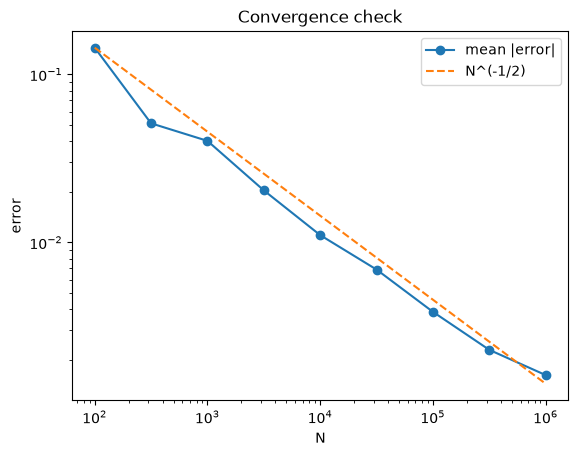

In [7]:
# Check 1: agreement with the analytic value within the 95% confidence interval
est, se = simulate(200_000, np.random.default_rng(SEED))
assert abs(est - np.pi) <= 1.96 * se, "estimate outside 95% CI of the analytic value"
print(f"PASS: |{est:.4f} - pi| = {abs(est-np.pi):.4f} <= {1.96*se:.4f}")

# Check 2 (error scaling): Monte Carlo error should fall like N^(-1/2)
Ns = np.logspace(2, 6, 9).astype(int)
errs = [np.mean([abs(simulate(n, np.random.default_rng(s))[0] - np.pi) for s in range(20)]) for n in Ns]
slope = np.polyfit(np.log(Ns), np.log(errs), 1)[0]
print(f"fitted slope = {slope:.2f} (expected about -0.5)")
assert -0.65 < slope < -0.35

plt.loglog(Ns, errs, "o-", label="mean |error|")
plt.loglog(Ns, errs[0] * (Ns / Ns[0])**-0.5, "--", label="N^(-1/2)")
plt.xlabel("N"); plt.ylabel("error"); plt.legend(); plt.title("Convergence check"); plt.show()

## 5. Experiments and results

[Parameter study or scenario comparison that answers your question. Report replications/seeds and confidence intervals, not single runs.]

In [8]:
# REPLACE: your parameter sweep or scenario comparison

## 6. Discussion and limitations

[What the results mean for the real-world question; the most important assumptions and their effect; what you would do next.]

**Web demo reference value:** with default settings the web demo should reproduce [value ± tolerance] from section [N].

## 7. References

1. [IEEE-style reference, with DOI or URL]